<a href="https://colab.research.google.com/github/bhavyak2207-cpu/exit_exam/blob/main/data_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [310]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("/content/drive/MyDrive/DSA/Exit exam/G2 (1).csv")
print("dataset is loaded sucessfully")

dataset is loaded sucessfully


In [311]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [312]:
df.shape

(1351, 10)

In [313]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [314]:
df.describe()

,id,height_dm,weight_hg,base_experience,hp,attack,defense
count,1351.000000,1351.000000,1351.000000,1302.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,161.943932,71.673575,82.757957,76.193930
std,4139.019112,53.238467,1953.115812,82.532554,26.827529,32.351906,30.712902
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000
25%,338.500000,6.000000,94.500000,71.000000,55.000000,60.000000,55.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000
75%,1013.500000,17.000000,853.500000,222.500000,85.000000,102.500000,95.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000


In [315]:
df.describe(include="object")

,name,type_1,type_2
count,1351,1351,765
unique,1351,18,18
top,bulbasaur,water,flying
freq,1,160,141


In [316]:
df.isnull().sum()

,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [317]:
df.isnull().sum()/len(df)*100

,0
id,0.000000
name,0.000000
height_dm,0.000000
weight_hg,0.000000
base_experience,3.626943
type_1,0.000000
type_2,43.375278
hp,0.000000
attack,0.000000
defense,0.000000


In [318]:
df.duplicated().sum()

np.int64(0)

In [319]:
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['id', 'height_dm', 'weight_hg', 'base_experience', 'hp', 'attack', 'defense']

Categorical Features: ['name', 'type_1', 'type_2']


In [320]:
df['type_1'].value_counts()

,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [321]:
print("\nTarget Percentage:")
print(df['type_1'].value_counts(normalize=True) * 100)


Target Percentage:
type_1
water       11.843079
normal      10.288675
grass        9.030348
electric     7.401925
bug          7.031828
psychic      6.365655
fire         6.217617
rock         6.143597
dark         4.663212
fighting     4.589193
dragon       4.367135
steel        3.849001
poison       3.849001
ghost        3.849001
ground       3.700962
ice          3.256847
fairy        2.590674
flying       0.962250
Name: proportion, dtype: float64


In [322]:
df['type_2'].value_counts()

,count
type_2,
flying,141
dragon,58
psychic,56
poison,54
fairy,53
steel,47
fighting,47
ground,46
ghost,44


Task 1:

1.the Pokemon type that appears most frequently in type 1 is the water .The water occurs around count of 160 and it contain 11.84 percentage as compared to others.while in type 2 the flying occurs most as compared to others.

2.THE greatest variation occurs in almost every feature except attack and defence.id can be removed because it contain all unique values which is not usefull for modelling and other fetuire like height and weight contain small varitions as the distribution of data is left skewed.these are insights about the features and its distribution.

3.the dataset contains missing values in type 2 and base experience which need to handled in preprocessing.the dataset contain (1351, 10) records in which ther is no duplicated values exist.the target variable contain 18 unique classesin which we use supervised classification methods for modelling.

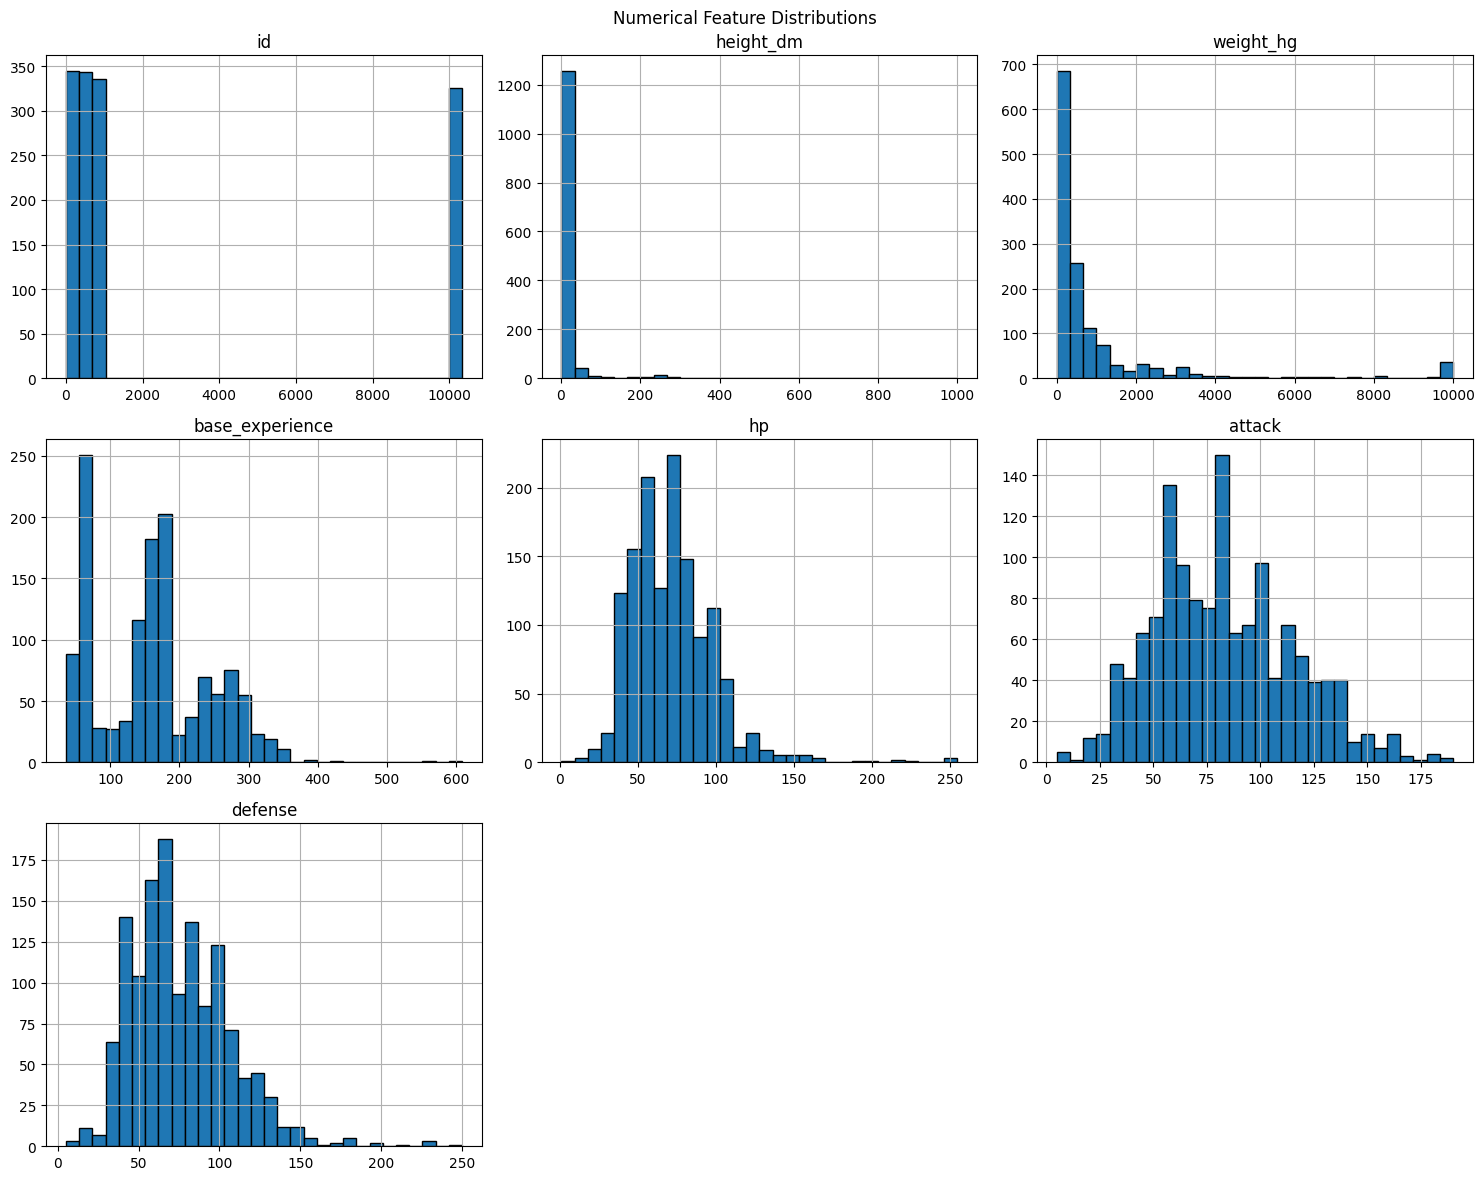

In [323]:
df[numerical_features].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

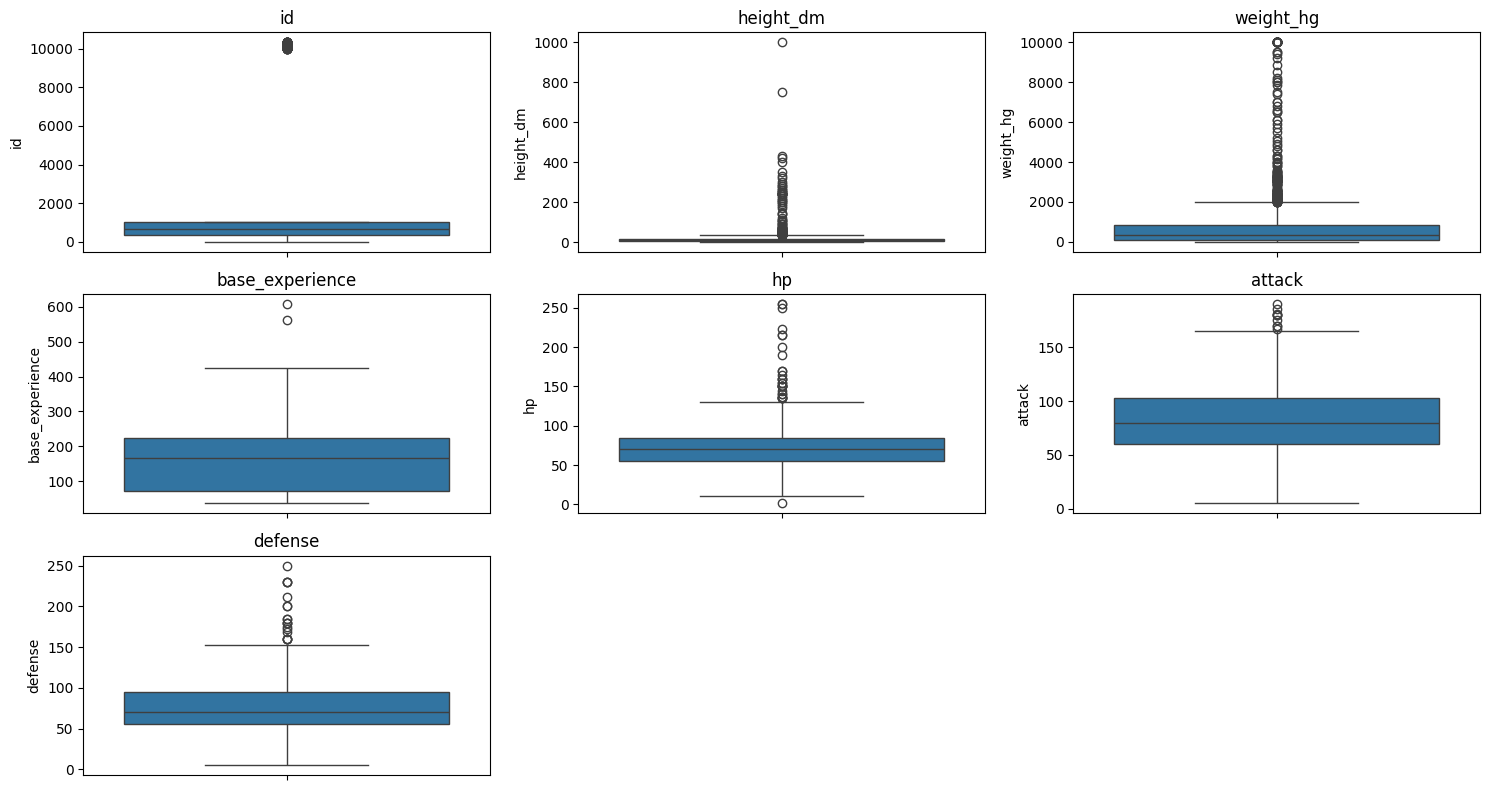

In [324]:
#Outlier visualization using boxplots
plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [325]:
for col in categorical_features:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts().head(10))


name
Unique values: 1351
name
bulbasaur     1
ivysaur       1
venusaur      1
charmander    1
charmeleon    1
charizard     1
squirtle      1
wartortle     1
blastoise     1
caterpie      1
Name: count, dtype: int64

type_1
Unique values: 18
type_1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
Name: count, dtype: int64

type_2
Unique values: 18
type_2
flying      141
dragon       58
psychic      56
poison       54
fairy        53
steel        47
fighting     47
ground       46
ghost        44
dark         36
Name: count, dtype: int64


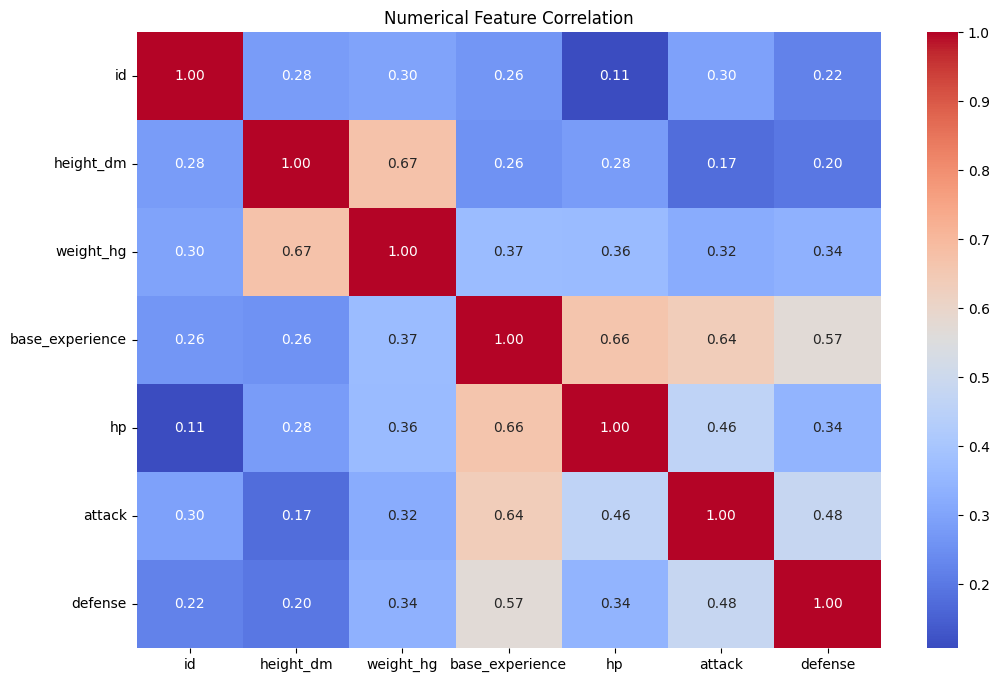

In [326]:
#Correlation analysis
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numerical_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Numerical Feature Correlation")
plt.show()

In [327]:
pd.crosstab(
    df['attack'],
    df['defense'],
    normalize='index'
) * 100

defense,5,10,15,20,23,25,28,30,31,32,...,160,168,172,175,180,184,200,211,230,250
attack,,,,,,,,,,,,,,,,,,,,,
5,100.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
10,0.0,33.333333,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.333333,0.0
15,0.0,0.000000,0.0,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
20,0.0,0.000000,10.0,20.000000,0.0,0.0,0.0,10.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
22,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
180,0.0,0.000000,0.0,33.333333,0.0,0.0,0.0,0.0,0.0,0.0,...,33.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
181,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0


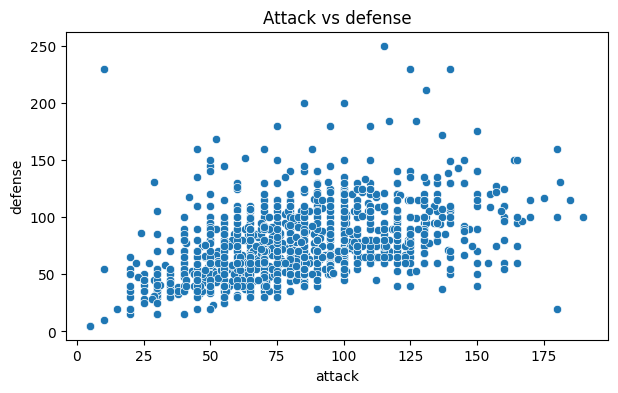

In [328]:
#attack vs defense
plt.figure(figsize=(7, 4))

sns.scatterplot(
        data=df,
        x='attack',
        y='defense'
    )

plt.title("Attack vs defense")
plt.show()

In [329]:
pd.crosstab(
    df['hp'],
    df['type_1'],
    normalize='index'
) * 100

type_1,bug,dark,dragon,electric,fairy,fighting,fire,flying,ghost,grass,ground,ice,normal,poison,psychic,rock,steel,water
hp,,,,,,,,,,,,,,,,,,
1,100.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000
10,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,66.666667,0.0,0.0,0.0,0.000000,0.0,0.0,33.333333
20,16.666667,0.0,0.0,16.666667,0.0,0.0,0.0,0.0,16.666667,0.0,0.000000,0.0,0.0,0.0,16.666667,0.0,0.0,33.333333
25,50.000000,0.0,0.0,25.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,25.000000,0.0,0.0,0.000000
28,0.000000,0.0,50.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,50.000000,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.000000,0.0,100.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000
216,0.000000,0.0,100.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000
223,0.000000,100.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000


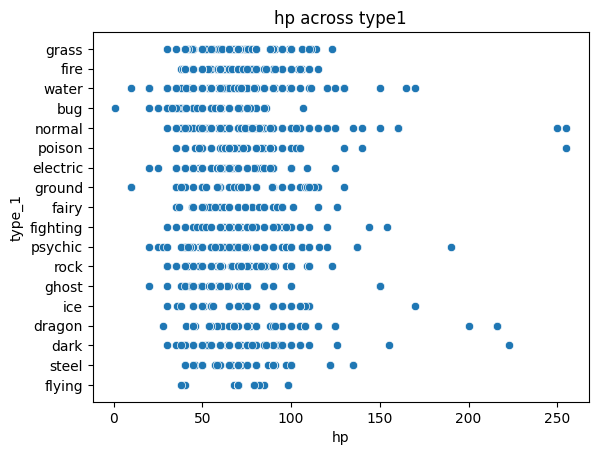

In [330]:
sns.scatterplot(
        data=df,
        x='hp',
        y='type_1'
    )

plt.title("hp across type1")
plt.show()

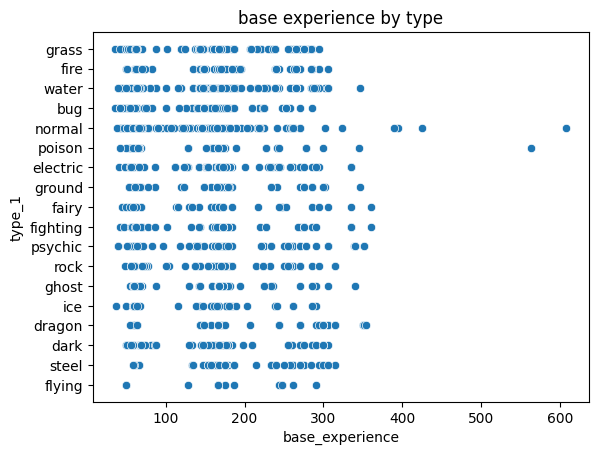

In [331]:
sns.scatterplot(
        data=df,
        x='base_experience',
        y='type_1'
    )

plt.title("base experience by type")
plt.show()

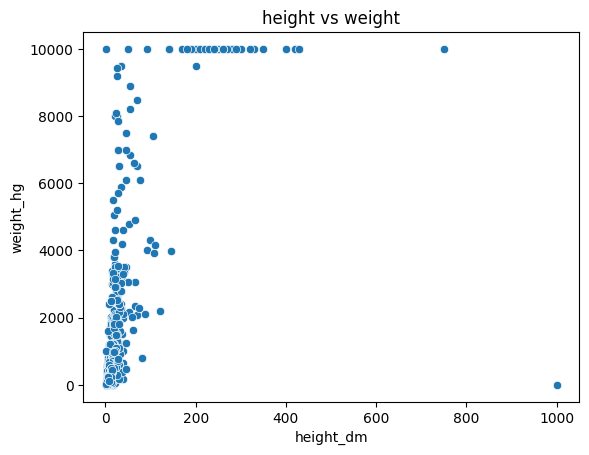

In [332]:
sns.scatterplot(
        data=df,
        x='height_dm',
        y='weight_hg'
    )

plt.title("height vs weight")
plt.show()

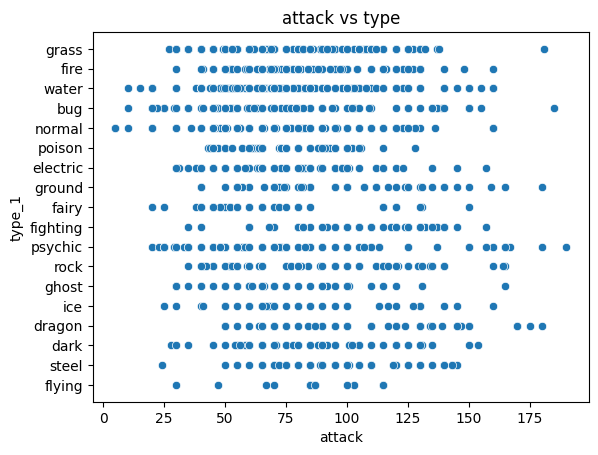

In [333]:
sns.scatterplot(
        data=df,
        x='attack',
        y='type_1'
    )

plt.title("attack vs type")
plt.show()

In [334]:
analysis = pd.DataFrame({
    'missing': df['type_2'].isna(),
    'type_1': df['type_1']
})

print(pd.crosstab(analysis['missing'], analysis['type_1'], normalize='index'))

type_1        bug      dark    dragon  electric     fairy  fighting      fire  \
missing                                                                         
False    0.094118  0.060131  0.058824  0.057516  0.014379  0.039216  0.060131   
True     0.039249  0.029010  0.023891  0.095563  0.040956  0.054608  0.064846   

type_1     flying     ghost     grass    ground       ice    normal    poison  \
missing                                                                         
False    0.011765  0.043137  0.095425  0.041830  0.028758  0.069281  0.045752   
True     0.006826  0.032423  0.083618  0.030717  0.037543  0.146758  0.029010   

type_1    psychic      rock     steel     water  
missing                                          
False    0.048366  0.082353  0.049673  0.099346  
True     0.083618  0.034130  0.023891  0.143345  


In [335]:
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

counts = pd.crosstab(df['type_2'].isna(), df['type_1'])
chi2, p_value, _, _ = chi2_contingency(counts)

n = counts.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(counts.shape[0] - 1, counts.shape[1] - 1)))

print(f'p-value: {p_value:.4g}')
print(f"Cramér's V: {cramers_v:.3f}")

p-value: 1.646e-14
Cramér's V: 0.277


Task 3:

1.here we created visualizations like scatterplot to analyse the relation of two features.the attack is high for features like psychic,bug,grass,dragon in this the avg attack is high for psychic this can be obserbed from the visualization.
2. Height and weight are not proportionate to each other. the height valius keep a constant range below 200 for every records above that there exist an outlier.but the weight is increases for the value of 10000 but height keeps a range of 200.it defines that both records have a linear realtionship together but keeping a range  
3.id and type 2 can be removed in identifying the pokemon type becuse it does not contain any useful information.according to current observation the there exist 8 imp features used for modelling  

In [336]:
df['type_2'].value_counts().sum()

np.int64(765)

In [337]:
# 11. Outlier Detection using IQR
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()


outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ).sum()

    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower_Limit': lower_limit,
        'Upper_Limit': upper_limit,
        'Outlier_Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count
0,id,338.5,1013.5,675.0,-674.00,2026.00,326
1,height_dm,6.0,17.0,11.0,-10.50,33.50,95
2,weight_hg,94.5,853.5,759.0,-1044.00,1992.00,174
3,base_experience,71.0,222.5,151.5,-156.25,449.75,2
4,hp,55.0,85.0,30.0,10.00,130.00,30
5,attack,60.0,102.5,42.5,-3.75,166.25,10
6,defense,55.0,95.0,40.0,-5.00,155.00,19


In [338]:
#  df['type_2'] = df['type_2'].fillna('None')
df = df.drop(columns='type_2')

In [339]:
# Separate input features and target variable

X = df.drop(columns=['id', 'type_1','name'])
y = df['type_1']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1351, 6)
Target shape: (1351,)

Target distribution:
type_1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
dragon       59
steel        52
poison       52
ghost        52
ground       50
ice          44
fairy        35
flying       13
Name: count, dtype: int64


In [340]:
# Identify numerical and categorical columns

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = X.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(list(numerical_cols))

print("\nCategorical columns:")
print(list(categorical_cols))

print("\nNumber of numerical features:", len(numerical_cols))
print("Number of categorical features:", len(categorical_cols))

Numerical columns:
['height_dm', 'weight_hg', 'base_experience', 'hp', 'attack', 'defense']

Categorical columns:
[]

Number of numerical features: 6
Number of categorical features: 0


In [341]:
print("Missing values in numerical features:")
print(X[numerical_cols].isnull().sum())

print("\nMissing values in categorical features:")
print(X[categorical_cols].isnull().sum())

print("\nTotal missing values:")
print(X.isnull().sum().sum())

Missing values in numerical features:
height_dm           0
weight_hg           0
base_experience    49
hp                  0
attack              0
defense             0
dtype: int64

Missing values in categorical features:
Series([], dtype: float64)

Total missing values:
49


In [342]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1080, 6)
X_test: (271, 6)
y_train: (1080,)
y_test: (271,)


In [343]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [344]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_pipeline = Pipeline(steps=[

    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [345]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ]
)

In [346]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (1080, 6)
Testing shape: (271, 6)


task 2:
1.preprocessing is required becuse the model training only requres essential features for prediction so this preprocessing will help to create the raw data into a formatted data using pipeline in which the model can train accuratly with usefull features.in preprocessing we perform- missing value handling type_2 is dropped and base experience is imputed using median then we keep the outliers as it it because the outliers are genine vaklues not errored value. then we do scailing and encoding for the features thta required using a pipeline.after preprocessing the data is ready for the model training and different models can be trained and tested using this splits.

2.the missing value in the type_2 is replaced with mode value because it is a categorical column. we anlysed the specific column with several methods we analysed that whether type 2 column is imp for type 1 prediction using the p value we found thta column cannot be dropped so we replaced the value with none and kept it for model training this is completed after training models we found only accracy with maximum of 30 so we tried by drop type 2 columns for further model evaluation and a slight increase in  accuracy occurs

In [347]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np
import time

In [348]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(n_neighbors=5),

    'SVM': SVC(
        class_weight='balanced',
        random_state=42
    )


}

In [349]:


trained_models = {}
all_predictions = {}
scores = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    all_predictions[name] = y_pred

    scores.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

# Compare models; macro F1 is useful when classes are imbalanced
results = pd.DataFrame(scores).sort_values('Macro F1', ascending=False)
print(results.to_string(index=False))

              Model  Accuracy  Macro F1
        Extra Trees  0.276753  0.246162
      Random Forest  0.243542  0.214541
      Decision Tree  0.221402  0.202712
                KNN  0.188192  0.160760
                SVM  0.132841  0.112924
Logistic Regression  0.140221  0.111485


In [352]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

         bug       0.12      0.21      0.16        19
        dark       0.00      0.00      0.00        13
      dragon       0.21      0.25      0.23        12
    electric       0.26      0.25      0.26        20
       fairy       0.03      0.14      0.05         7
    fighting       0.17      0.33      0.22        12
        fire       0.00      0.00      0.00        17
      flying       0.06      0.67      0.10         3
       ghost       0.20      0.10      0.13        10
       grass       0.00      0.00      0.00        25
      ground       0.17      0.10      0.12        10
         ice       0.00      0.00      0.00         9
      normal       0.18      0.21      0.19        28
      poison       0.00      0.00      0.00        10
     psychic       0.05      0.06      0.05        17
        rock       0.31      0.24      0.27        17
       steel       0.17      0.40      0.24        10
       water       0.00    

In [353]:
!pip install catboost
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Use your existing X_train, X_test, y_train, y_test.
# Fill missing categorical values; CatBoost handles numeric NaNs.
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].fillna('Unknown').astype(str)
    X_test_cb[col] = X_test_cb[col].fillna('Unknown').astype(str)

cat_model = CatBoostClassifier(
    iterations=800,
    depth=6,
    learning_rate=0.05,
    loss_function='MultiClass',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100
)

cat_model.fit(X_train_cb, y_train, cat_features=cat_cols)
cat_pred = cat_model.predict(X_test_cb).ravel()

print("Accuracy:", accuracy_score(y_test, cat_pred))
print("Macro F1:", f1_score(y_test, cat_pred, average='macro', zero_division=0))
print(classification_report(y_test, cat_pred, zero_division=0))

0:	learn: 2.8713926	total: 34.4ms	remaining: 27.4s
100:	learn: 2.1153939	total: 2.54s	remaining: 17.5s
200:	learn: 1.7587906	total: 5.49s	remaining: 16.4s
300:	learn: 1.5132814	total: 7.56s	remaining: 12.5s
400:	learn: 1.3086471	total: 9.87s	remaining: 9.82s
500:	learn: 1.1537909	total: 12.3s	remaining: 7.36s
600:	learn: 1.0214741	total: 14.1s	remaining: 4.66s
700:	learn: 0.9072545	total: 15.6s	remaining: 2.21s
799:	learn: 0.8121629	total: 17.2s	remaining: 0us
Accuracy: 0.2656826568265683
Macro F1: 0.23553410493940583
              precision    recall  f1-score   support

         bug       0.38      0.42      0.40        19
        dark       0.22      0.15      0.18        13
      dragon       0.31      0.33      0.32        12
    electric       0.54      0.35      0.42        20
       fairy       0.11      0.14      0.12         7
    fighting       0.29      0.33      0.31        12
        fire       0.20      0.29      0.24        17
      flying       0.00      0.00      0.00

In [354]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from catboost import CatBoostClassifier

# Split only the training data; preserve X_test for final evaluation.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

cat_cols = X_fit.select_dtypes(include=['object', 'category']).columns.tolist()

for frame in (X_fit, X_valid, X_test):
    for col in cat_cols:
        frame[col] = frame[col].fillna('Unknown').astype(str)

cat_model = CatBoostClassifier(
    iterations=1500,
    depth=5,                       # Shallower trees can reduce overfitting
    learning_rate=0.03,
    loss_function='MultiClass',
    eval_metric='TotalF1:average=Macro',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100
)

cat_model.fit(
    X_fit,
    y_fit,
    cat_features=cat_cols,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True
)

cat_pred = cat_model.predict(X_test).ravel()

print("CatBoost accuracy:", accuracy_score(y_test, cat_pred))
print("CatBoost macro F1:", f1_score(
    y_test, cat_pred, average='macro', zero_division=0
))
print(classification_report(y_test, cat_pred, zero_division=0))

0:	learn: 0.1032532	test: 0.0439323	best: 0.0439323 (0)	total: 9.16ms	remaining: 13.7s
100:	learn: 0.3552317	test: 0.1353370	best: 0.1488127 (12)	total: 884ms	remaining: 12.2s
200:	learn: 0.4644531	test: 0.1656115	best: 0.1699296 (163)	total: 1.89s	remaining: 12.2s
300:	learn: 0.5599391	test: 0.1856539	best: 0.1868766 (286)	total: 2.79s	remaining: 11.1s
400:	learn: 0.6154520	test: 0.1902547	best: 0.1962813 (369)	total: 3.58s	remaining: 9.8s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.1962812935
bestIteration = 369

Shrink model to first 370 iterations.
CatBoost accuracy: 0.17712177121771217
CatBoost macro F1: 0.1749970914898176
              precision    recall  f1-score   support

         bug       0.33      0.32      0.32        19
        dark       0.29      0.15      0.20        13
      dragon       0.19      0.25      0.21        12
    electric       0.50      0.30      0.38        20
       fairy       0.11      0.14      0.12         7
    fighting  

In [357]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

min_class_count = int(y_train.value_counts().min())
n_splits = min(5, min_class_count)

if n_splits < 2:
    print("At least one class has only one training example; stratified CV isn't possible.")
else:
    et_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', ExtraTreesClassifier(random_state=42, n_jobs=-1))
    ])

    param_distributions = {
        'model__n_estimators': [300, 500, 800],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__max_features': ['sqrt', 0.5, None],
        'model__class_weight': [None, 'balanced', 'balanced_subsample'],
        'model__criterion': ['gini', 'entropy', 'log_loss']
    }

    search = RandomizedSearchCV(
        estimator=et_pipeline,
        param_distributions=param_distributions,
        n_iter=40,
        scoring='f1_macro',
        cv=StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=42
        ),
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    test_pred = best_model.predict(X_test)

    print("Best parameters:", search.best_params_)
    print("Best CV macro F1:", search.best_score_)
    print("Test accuracy:", accuracy_score(y_test, test_pred))
    print("Test macro F1:", f1_score(
        y_test, test_pred, average='macro', zero_division=0
    ))
    print(classification_report(y_test, test_pred, zero_division=0))

Fitting 5 folds for each of 40 candidates, totalling 200 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'model__n_estimators': 800, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30, 'model__criterion': 'log_loss', 'model__class_weight': None}
Best CV macro F1: 0.22660831599749348
Test accuracy: 0.2693726937269373
Test macro F1: 0.23913066256097748
              precision    recall  f1-score   support

         bug       0.31      0.42      0.36        19
        dark       0.17      0.08      0.11        13
      dragon       0.31      0.33      0.32        12
    electric       0.41      0.35      0.38        20
       fairy       0.33      0.29      0.31         7
    fighting       0.29      0.17      0.21        12
        fire       0.16      0.18      0.17        17
      flying       0.00      0.00      0.00         3
       ghost       0.67      0.20      0.31        10
       grass       0.25      0.24      0.24        25
      ground       0.50      0.20      0.29        10
         ice       0.00 

In [358]:
import pandas as pd

comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': test_pred
})

# Types most often incorrectly predicted, with their error rates
wrong = comparison[comparison['Actual'] != comparison['Predicted']]

summary = pd.DataFrame({
    'Misclassified': wrong['Actual'].value_counts(),
    'Total': y_test.value_counts(),
})
summary['Misclassified'] = summary['Misclassified'].fillna(0).astype(int)
summary['Error rate'] = summary['Misclassified'] / summary['Total']

print(summary.sort_values('Misclassified', ascending=False))

          Misclassified  Total  Error rate
water                22     32    0.687500
normal               20     28    0.714286
grass                19     25    0.760000
fire                 14     17    0.823529
electric             13     20    0.650000
dark                 12     13    0.923077
bug                  11     19    0.578947
psychic              10     17    0.588235
fighting             10     12    0.833333
ice                   9      9    1.000000
rock                  9     17    0.529412
poison                9     10    0.900000
dragon                8     12    0.666667
ghost                 8     10    0.800000
ground                8     10    0.800000
steel                 8     10    0.800000
fairy                 5      7    0.714286
flying                3      3    1.000000


In [359]:
confusion_pairs = (
    wrong.groupby(['Actual', 'Predicted'])
         .size()
         .sort_values(ascending=False)
)

print(confusion_pairs.head(15))

Actual    Predicted
normal    water        5
poison    water        5
electric  grass        4
grass     psychic      4
normal    fire         4
grass     water        4
dragon    water        3
water     normal       3
          grass        3
          fire         3
psychic   water        3
water     psychic      3
steel     rock         3
water     bug          3
steel     water        3
dtype: int64


In [360]:
import pandas as pd

# test_pred should contain predictions for X_test, in the same row order
evaluation = pd.DataFrame({
    'actual': y_test,
    'predicted': test_pred
}, index=y_test.index)
evaluation['correct'] = evaluation['actual'] == evaluation['predicted']

# How often each actual type was misclassified
error_summary = evaluation.groupby('actual').agg(
    support=('correct', 'size'),
    correct=('correct', 'sum')
)
error_summary['errors'] = error_summary['support'] - error_summary['correct']
error_summary['error_rate'] = error_summary['errors'] / error_summary['support']

print(error_summary.sort_values('error_rate', ascending=False))

          support  correct  errors  error_rate
actual                                        
ice             9        0       9    1.000000
flying          3        0       3    1.000000
dark           13        1      12    0.923077
poison         10        1       9    0.900000
fighting       12        2      10    0.833333
fire           17        3      14    0.823529
steel          10        2       8    0.800000
ground         10        2       8    0.800000
ghost          10        2       8    0.800000
grass          25        6      19    0.760000
fairy           7        2       5    0.714286
normal         28        8      20    0.714286
water          32       10      22    0.687500
dragon         12        4       8    0.666667
electric       20        7      13    0.650000
psychic        17        7      10    0.588235
bug            19        8      11    0.578947
rock           17        8       9    0.529412


In [361]:
numeric_cols = X_test.select_dtypes(include='number').columns.tolist()
overall_std = X_test[numeric_cols].std().replace(0, pd.NA)

differences = []

for pokemon_type, rows in evaluation.groupby('actual'):
    correct_idx = rows.index[rows['correct']]
    wrong_idx = rows.index[~rows['correct']]

    # Need examples in both groups to make a comparison
    if len(correct_idx) == 0 or len(wrong_idx) == 0:
        continue

    correct_means = X_test.loc[correct_idx, numeric_cols].mean()
    wrong_means = X_test.loc[wrong_idx, numeric_cols].mean()

    # Difference in standard deviations, so features are comparable
    shifts = (wrong_means - correct_means) / overall_std

    for feature in shifts.abs().nlargest(5).index:
        differences.append({
            'Actual type': pokemon_type,
            'Feature': feature,
            'Correct mean': correct_means[feature],
            'Misclassified mean': wrong_means[feature],
            'Difference (std devs)': shifts[feature]
        })

print(pd.DataFrame(differences).to_string(index=False))

Actual type         Feature  Correct mean  Misclassified mean  Difference (std devs)
        bug base_experience    122.875000          182.636364               0.756080
        bug       weight_hg    317.375000         1210.727273               0.444462
        bug       height_dm      9.250000           22.090909               0.330426
        bug         defense     78.750000           86.909091               0.257178
        bug              hp     54.875000           59.909091               0.215519
       dark          attack    130.000000           90.583333              -1.206148
       dark         defense     60.000000           79.750000               0.622529
       dark              hp     65.000000           76.500000               0.492338
       dark base_experience    163.000000          191.727273               0.363447
       dark       height_dm     12.000000           15.166667               0.081486
     dragon base_experience    291.000000          124.200000    

task 4:

1.currently extra tress found best accuracy as comparing multiple models and after tuning that model we found 26 accuracy

2.water is mopst misclassified ammoung all the other classes

3.Misclassified Pokémon often differed from correctly classified Pokémon of the same type in their numerical stats. The largest observed differences were for dragon base experience and HP, steel weight and battle stats, rock HP, and psychic attack. These are exploratory patterns from the test set, not evidence of causation; small class counts mean they should be interpreted cautiously.


In [362]:
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Remove rows without a target, then prepare features and target
data = df.dropna(subset=['type_1']).copy()

X = data.drop(
    columns=['type_1', 'id', 'name', 'type_2'],
    errors='ignore'
)
y = data['type_1']

# Detect columns for preprocessing
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', SimpleImputer(strategy='median'), numeric_cols),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ],
    remainder='drop'
)

final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', ExtraTreesClassifier(
        n_estimators=800,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.5,
        max_depth=30,
        criterion='log_loss',
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

# Keep this split consistent with the one used for your reported results
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

final_model.fit(X_train, y_train)
test_pred = final_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, test_pred))
print("Macro F1:", f1_score(
    y_test, test_pred, average='macro', zero_division=0
))
print(classification_report(y_test, test_pred, zero_division=0))

# Save the fitted pipeline, including its preprocessing
joblib.dump(final_model, 'pokemon_type1_extra_trees.joblib')

Accuracy: 0.2693726937269373
Macro F1: 0.23913066256097748
              precision    recall  f1-score   support

         bug       0.31      0.42      0.36        19
        dark       0.17      0.08      0.11        13
      dragon       0.31      0.33      0.32        12
    electric       0.41      0.35      0.38        20
       fairy       0.33      0.29      0.31         7
    fighting       0.29      0.17      0.21        12
        fire       0.16      0.18      0.17        17
      flying       0.00      0.00      0.00         3
       ghost       0.67      0.20      0.31        10
       grass       0.25      0.24      0.24        25
      ground       0.50      0.20      0.29        10
         ice       0.00      0.00      0.00         9
      normal       0.30      0.29      0.29        28
      poison       0.10      0.10      0.10        10
     psychic       0.30      0.41      0.35        17
        rock       0.44      0.47      0.46        17
       steel       0.1

['pokemon_type1_extra_trees.joblib']

In [363]:
from google.colab import files

files.download('/content/pokemon_type1_extra_trees.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>